# Bean leaf disease classification: training, evaluation and retraining

This notebook trains an image classifier that labels a photo of a bean leaf as **healthy**, **angular leaf spot** or **bean rust**.

Beans are a staple crop and a main source of protein for smallholder farmers in Rwanda and across East Africa. A phone photo that flags disease early can save part of a harvest (SDG 2, Zero Hunger; SDG 1, No Poverty).

**Dataset:** [iBean](https://github.com/AI-Lab-Makerere/ibean) from the Makerere AI Lab and Uganda's National Crops Resources Research Institute: 1,295 field photos of bean leaves, 500x500 px, three classes.

**Steps in this notebook**
1. Data acquisition
2. Data exploration: what the images and their features tell us
3. Preprocessing
4. Model creation (MobileNetV2 transfer learning)
5. Training: stage 1 (frozen base), stage 2 (fine-tuning)
6. Evaluation on the held-out test set: accuracy, loss, precision, recall, F1, confusion matrix, ROC-AUC
7. Prediction functions
8. Retraining from the saved model

All data handling, model and prediction code lives in `src/`, so the API in production runs the same code as this notebook.

## 0. Setup

In [1]:
# On Google Colab: clone the repo and work from its notebook/ folder so that
# the ../src and ../data paths are the same as on a local machine.
import sys, os
if 'google.colab' in sys.modules:
    REPO_URL = 'https://github.com/Keaane/Beanleaf_disease_pipeline.git'
    if not os.path.exists('/content/repo'):
        !git clone -q $REPO_URL /content/repo
    %cd /content/repo/notebook

In [2]:
import os, sys, json, random, time
sys.path.insert(0, os.path.abspath('../src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize

from preprocessing import (CLASS_NAMES, NUM_CLASSES, IMG_SIZE, download_ibean, list_images,
                           class_counts, stratified_split, make_dataset, preprocess_image,
                           decode_image, image_features)
from model import (build_model, train_model, fine_tune_model, evaluate_model,
                   predict_dataset, save_model, retrain_model)
from prediction import predict_image

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_style('whitegrid')
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('jpeg')  # keeps the notebook small enough for GitHub to render
plt.rcParams['figure.dpi'] = 72
os.makedirs('../ui/img', exist_ok=True)
os.makedirs('../ui/data', exist_ok=True)

PRETTY = {'angular_leaf_spot': 'Angular leaf spot', 'bean_rust': 'Bean rust', 'healthy': 'Healthy'}
PALETTE = {'angular_leaf_spot': '#C9822B', 'bean_rust': '#A23B2A', 'healthy': '#3C8D3F'}
print('TensorFlow', tf.__version__)

I0000 00:00:1795614858.398542   16873 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795614861.025153   16873 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 1. Data acquisition

The images are already in the repo under `data/train` and `data/test` (one folder per class). If those folders are empty, `download_ibean()` fetches iBean from Hugging Face (`AI-Lab-Makerere/beans`) and writes them.

- `data/train` = iBean train + validation splits. I carve my own stratified 15% validation set out of it.
- `data/test` = iBean test split. It is never used for training or early stopping, only for the final evaluation.

In [3]:
TRAIN_DIR, TEST_DIR = '../data/train', '../data/test'
if sum(class_counts(TRAIN_DIR).values()) == 0:
    print('Data folders empty, downloading iBean...')
    print(download_ibean('../data'))

all_paths, all_labels = list_images(TRAIN_DIR)
test_paths, test_labels = list_images(TEST_DIR)
train_paths, train_labels, val_paths, val_labels = stratified_split(all_paths, all_labels, val_fraction=0.15, seed=SEED)

split_table = pd.DataFrame({
    'train': pd.Series(train_labels).map(dict(enumerate(CLASS_NAMES))).value_counts(),
    'validation': pd.Series(val_labels).map(dict(enumerate(CLASS_NAMES))).value_counts(),
    'test': pd.Series(test_labels).map(dict(enumerate(CLASS_NAMES))).value_counts(),
}).loc[CLASS_NAMES]
split_table.loc['total'] = split_table.sum()
split_table

,train,validation,test
angular_leaf_spot,318,56,43
bean_rust,321,57,43
healthy,314,56,42
total,953,169,128


## 2. Data exploration

I look at the dataset through six views. The first two describe the data as a whole; the other four are features measured on every training image:

1. **Class distribution**: is the dataset balanced?
2. **Sample images**: what does each disease look like?
3. **Brightness**: mean pixel value. Could lighting alone give the class away?
4. **Green fraction**: share of pixels where green clearly dominates (healthy leaf tissue).
5. **Lesion fraction**: share of brown, yellow and rust coloured pixels (dead or infected tissue).
6. **Edge density**: share of pixels on a strong edge (spots, lesion borders, veins, background).

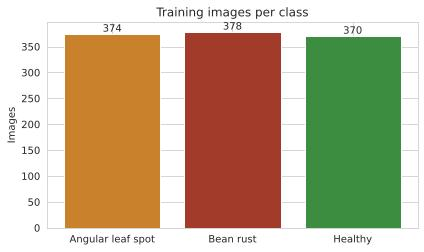

In [4]:
# Feature 1: class distribution
counts = pd.Series(class_counts(TRAIN_DIR))
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.bar([PRETTY[c] for c in counts.index], counts.values, color=[PALETTE[c] for c in counts.index])
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, str(v), ha='center')
ax.set_ylabel('Images'); ax.set_title('Training images per class')
plt.tight_layout(); plt.savefig('../ui/img/class_distribution.png', dpi=110); plt.show()

**Interpretation.** The three classes are almost exactly balanced (370 to 378 images each). A model cannot reach high accuracy by favouring one class, so plain accuracy is a fair headline metric here and I did not need class weights or oversampling. I still report macro precision, recall and F1 so that a weak class cannot hide behind the average.

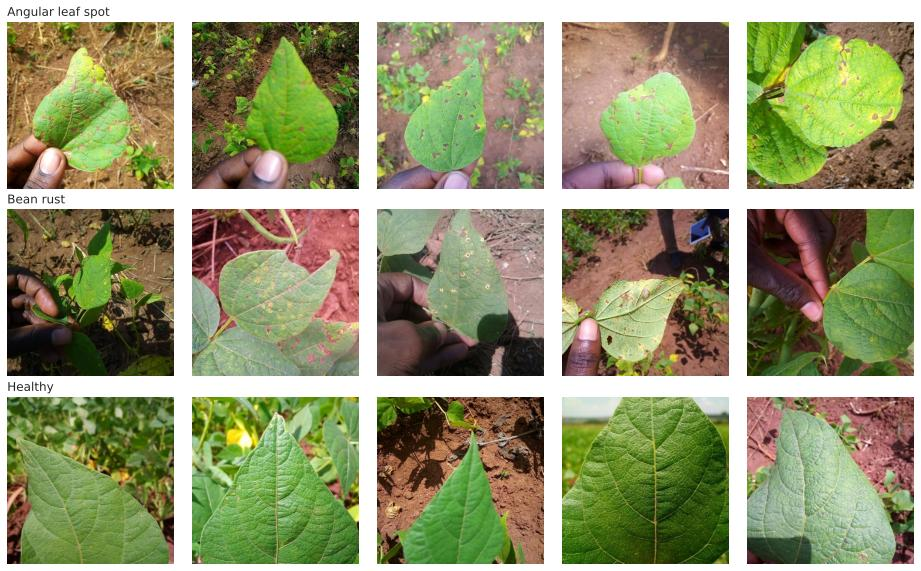

In [5]:
# Feature 2: sample images per class
fig, axes = plt.subplots(3, 5, figsize=(13, 8))
rng = random.Random(1)
for row, c in enumerate(CLASS_NAMES):
    picks = rng.sample([p for p, l in zip(all_paths, all_labels) if l == row], 5)
    for col, p in enumerate(picks):
        axes[row, col].imshow(plt.imread(p)); axes[row, col].axis('off')
        if col == 0:
            axes[row, col].set_title(PRETTY[c], loc='left', fontsize=12)
plt.tight_layout(); plt.savefig('../ui/img/sample_images.png', dpi=80); plt.show()

**Interpretation.** Angular leaf spot shows angular grey-brown patches bounded by the leaf veins. Bean rust shows many small, round, reddish-brown pustules spread over the leaf. Healthy leaves are evenly green. The photos are taken in the field, so many include soil, hands, stems and other leaves in the background. The model has to find the leaf and its texture, not just a colour.

In [6]:
# Features 3-6: colour and texture measurements on every training image
t0 = time.time()
feat_df = pd.DataFrame([dict(image_features(p), label=CLASS_NAMES[l]) for p, l in zip(all_paths, all_labels)])
print(f'Computed features for {len(feat_df)} images in {time.time() - t0:.0f}s')
FEATURES = ['brightness', 'green_fraction', 'lesion_fraction', 'edge_density']
summary = feat_df.groupby('label')[FEATURES].agg(['mean', 'median', 'std']).round(3)
summary

Computed features for 1122 images in 5s


brightness                  green_fraction                \
                        mean   median     std           mean median    std   
label                                                                        
angular_leaf_spot    111.198  112.238  20.424          0.471  0.453  0.187   
bean_rust            106.256  111.026  22.450          0.446  0.435  0.168   
healthy              115.636  115.786  19.217          0.696  0.717  0.160   

                  lesion_fraction               edge_density                
                             mean median    std         mean median    std  
label                                                                       
angular_leaf_spot           0.447  0.462  0.187        0.182  0.165  0.099  
bean_rust                   0.444  0.453  0.157        0.202  0.188  0.102  
healthy                     0.234  0.215  0.132        0.235  0.233  0.085

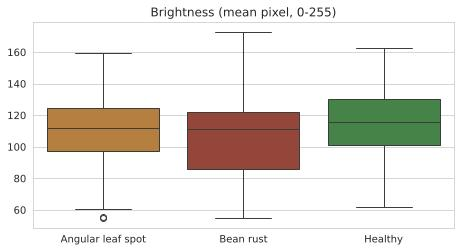

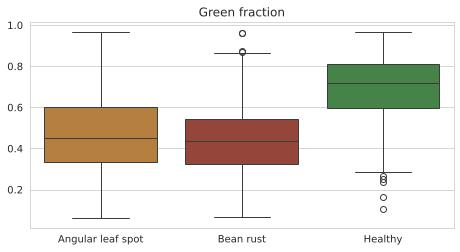

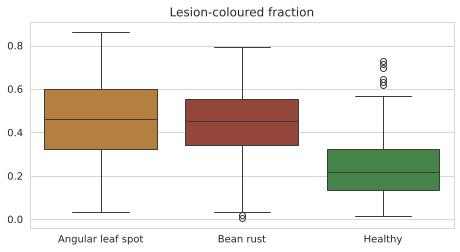

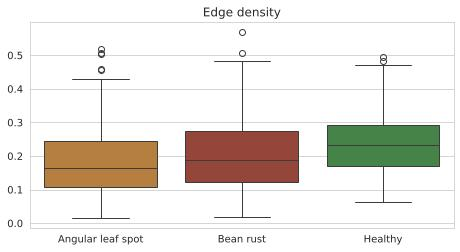

In [7]:
titles = {'brightness': 'Brightness (mean pixel, 0-255)', 'green_fraction': 'Green fraction',
          'lesion_fraction': 'Lesion-coloured fraction', 'edge_density': 'Edge density'}
files = {'brightness': 'feature_brightness.png', 'green_fraction': 'feature_green_fraction.png',
         'lesion_fraction': 'feature_lesion_fraction.png', 'edge_density': 'feature_edge_density.png'}
for f in FEATURES:
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    sns.boxplot(data=feat_df, x='label', y=f, hue='label', order=CLASS_NAMES, palette=PALETTE, legend=False, ax=ax)
    ax.set_xticks(range(3)); ax.set_xticklabels([PRETTY[c] for c in CLASS_NAMES])
    ax.set_xlabel(''); ax.set_ylabel(''); ax.set_title(titles[f])
    plt.tight_layout(); plt.savefig('../ui/img/' + files[f], dpi=110); plt.show()

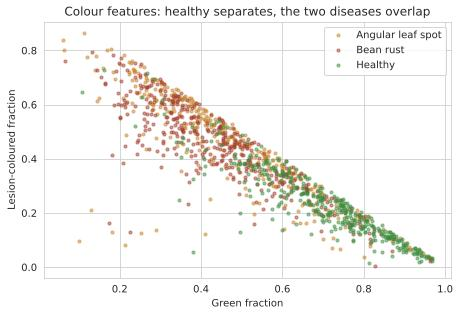

In [8]:
# Scatter of the two colour features: how far do colour features alone go?
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for c in CLASS_NAMES:
    d = feat_df[feat_df.label == c]
    ax.scatter(d.green_fraction, d.lesion_fraction, s=10, alpha=0.5, color=PALETTE[c], label=PRETTY[c])
ax.set_xlabel('Green fraction'); ax.set_ylabel('Lesion-coloured fraction'); ax.legend()
ax.set_title('Colour features: healthy separates, the two diseases overlap')
plt.tight_layout(); plt.savefig('../ui/img/feature_scatter.png', dpi=110); plt.show()

# Save the per-class feature summary for the UI's Data tab.
ui_summary = {c: {f: round(float(feat_df[feat_df.label == c][f].median()), 3) for f in FEATURES} for c in CLASS_NAMES}
json.dump({'class_counts': counts.to_dict(), 'feature_medians': ui_summary}, open('../ui/data/feature_summary.json', 'w'), indent=2)

**Interpretation: brightness.** The three boxes overlap almost completely. Bean rust photos are slightly darker on average, but the difference is small next to the spread inside each class. Lighting is not a shortcut the model could use instead of the disease itself, which is good: a farmer's photo in different light should still be classified on the leaf's condition.

**Interpretation: green fraction.** This is the clearest single feature. In a typical healthy photo about 70% of pixels are green-dominant, against about 45% for both diseases, because infected tissue turns brown or yellow. Healthy against diseased is mostly a colour question.

**Interpretation: lesion-coloured fraction.** This is the mirror image: both diseases have roughly twice the brown and yellow area of healthy leaves. Healthy photos are not at zero because soil and dry stems in the background share the same colours.

**Interpretation: edge density.** This one surprised me. Healthy photos have slightly *more* edges, not fewer. Edges here come mostly from veins, leaf outlines and busy backgrounds rather than from the disease spots, so this simple feature does not capture the lesion texture.

**The story.** Healthy against diseased can almost be told apart by colour alone. Angular leaf spot against bean rust cannot: their boxes and the scatter overlap on every simple feature. What separates them is the *shape and pattern* of the lesions (angular patches bounded by veins vs small round pustules). That is why I use a convolutional network that learns spatial patterns, and why the confusion matrix later shows most of the remaining errors between the two diseases.

## 3. Preprocessing

All steps are in `src/preprocessing.py` and are reused by the API:

1. Decode the JPEG to RGB (uint8).
2. Resize to 224x224, the input size of MobileNetV2.
3. Scale pixels to [0, 1] (the model's first layer rescales to [-1, 1] for MobileNetV2).
4. Training split only, data augmentation: random horizontal and vertical flips, random zoom-crop (80-100%), brightness, contrast and saturation jitter. This makes up for the small dataset and for the different ways farmers hold the phone.
5. Images are read from disk lazily in batches of 32 through `tf.data`, with prefetching.

Batch: (32, 224, 224, 3) <dtype: 'float32'> | labels: (32,) | pixel range: 0.00-1.00


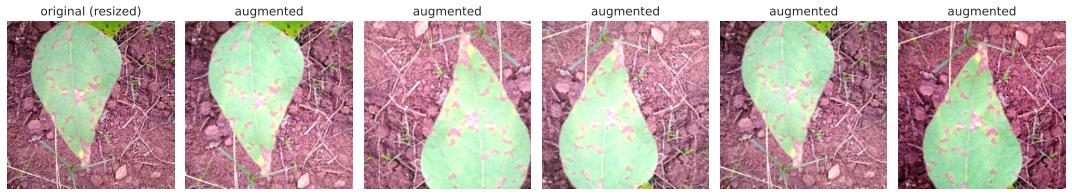

In [9]:
BATCH_SIZE = 32
train_ds = make_dataset(train_paths, train_labels, BATCH_SIZE, augment=True, shuffle=True, seed=SEED)
val_ds = make_dataset(val_paths, val_labels, BATCH_SIZE)
test_ds = make_dataset(test_paths, test_labels, BATCH_SIZE)

x, y = next(iter(train_ds))
print('Batch:', x.shape, x.dtype, '| labels:', y.shape, '| pixel range: %.2f-%.2f' % (x.numpy().min(), x.numpy().max()))

# Show one image with several random augmentations
raw = decode_image(tf.io.read_file(train_paths[0]))
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
axes[0].imshow(preprocess_image(raw)); axes[0].set_title('original (resized)')
for ax in axes[1:]:
    ax.imshow(preprocess_image(raw, augment=True)); ax.set_title('augmented')
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

## 4. Model creation

With about 1,000 training images, a CNN trained from scratch would overfit. I use **transfer learning**: MobileNetV2 pre-trained on ImageNet as a feature extractor, plus a small head of my own:

`Rescaling -> MobileNetV2 (frozen) -> GlobalAveragePooling -> Dropout(0.3) -> Dense(128, ReLU, L2) -> Dropout(0.15) -> Dense(3, softmax, L2)`

MobileNetV2 is small (about 2.4M parameters) and fast on CPU, which matters for serving it on a free cloud instance.

**Optimisation techniques used**
| Technique | Where |
|---|---|
| Pre-trained model (MobileNetV2, ImageNet) | base network |
| Two-stage training: frozen base, then fine-tuning the top 60 layers | stages 1 and 2 |
| Adam optimiser, learning rate 1e-3 (stage 1), 3e-5 (stage 2) | compile |
| L2 regularisation (1e-4) and dropout (0.3 / 0.15) | head |
| Early stopping on validation loss, best weights restored | callbacks |
| ReduceLROnPlateau (x0.3 when validation loss stalls) | callbacks |
| Data augmentation | training pipeline |

In [10]:
model = build_model(dropout=0.3, l2=1e-4, learning_rate=1e-3)
model.summary()

Model: "bean_leaf_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Training

### Stage 1: train the head, base frozen

In [11]:
t0 = time.time()
hist1 = train_model(model, train_ds, val_ds, epochs=20, patience=4, verbose=2)
print(f'Stage 1: {len(hist1.history["loss"])} epochs in {(time.time() - t0) / 60:.1f} min')
stage1_metrics = evaluate_model(model, test_ds)
print('Stage 1 test accuracy: %.4f | macro F1: %.4f' % (stage1_metrics['accuracy'], stage1_metrics['f1']))

Epoch 1/20


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


30/30 - 20s - 669ms/step - accuracy: 0.6432 - loss: 0.7982 - val_accuracy: 0.8225 - val_loss: 0.4031 - learning_rate: 0.0010


Epoch 2/20


30/30 - 19s - 621ms/step - accuracy: 0.8258 - loss: 0.4664 - val_accuracy: 0.8284 - val_loss: 0.3753 - learning_rate: 0.0010


Epoch 3/20


... (33 outputs left out)

Epoch 20/20


30/30 - 21s - 709ms/step - accuracy: 0.9224 - loss: 0.2238 - val_accuracy: 0.9467 - val_loss: 0.2028 - learning_rate: 9.0000e-05


Stage 1: 20 epochs in 5.8 min


Stage 1 test accuracy: 0.9141 | macro F1: 0.9138


### Stage 2: fine-tune the top 60 layers of MobileNetV2 at a low learning rate

In [12]:
t0 = time.time()
hist2 = fine_tune_model(model, train_ds, val_ds, n_trainable=60, learning_rate=3e-5, epochs=15, patience=5, verbose=2)
print(f'Stage 2: {len(hist2.history["loss"])} epochs in {(time.time() - t0) / 60:.1f} min')
print('Trainable parameters after unfreezing:', sum(int(np.prod(w.shape)) for w in model.trainable_weights))

Epoch 1/15


/usr/local/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


30/30 - 26s - 850ms/step - accuracy: 0.8909 - loss: 0.2861 - val_accuracy: 0.9053 - val_loss: 0.2296 - learning_rate: 3.0000e-05


Epoch 2/15


30/30 - 21s - 709ms/step - accuracy: 0.9255 - loss: 0.2172 - val_accuracy: 0.8876 - val_loss: 0.2677 - learning_rate: 3.0000e-05


Epoch 3/15


... (22 outputs left out)

30/30 - 21s - 702ms/step - accuracy: 0.9780 - loss: 0.0810 - val_accuracy: 0.9586 - val_loss: 0.1177 - learning_rate: 2.7000e-06


Epoch 15/15


30/30 - 22s - 719ms/step - accuracy: 0.9801 - loss: 0.0747 - val_accuracy: 0.9586 - val_loss: 0.1371 - learning_rate: 2.7000e-06


Stage 2: 15 epochs in 5.8 min
Trainable parameters after unfreezing: 2096131


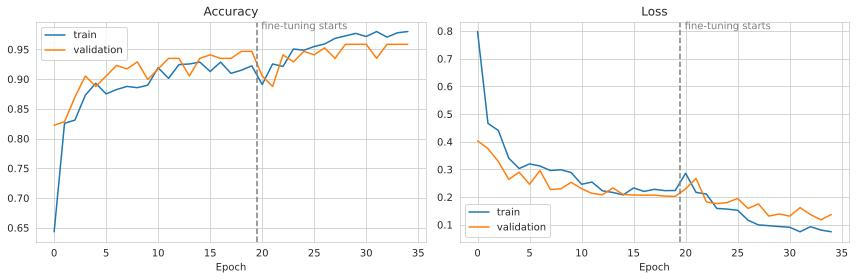

In [13]:
def joined(key):
    return hist1.history[key] + hist2.history[key]
n1 = len(hist1.history['loss'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, title in [(axes[0], 'accuracy', 'Accuracy'), (axes[1], 'loss', 'Loss')]:
    ax.plot(joined(key), label='train'); ax.plot(joined('val_' + key), label='validation')
    ax.axvline(n1 - 0.5, color='grey', ls='--'); ax.text(n1 - 0.4, ax.get_ylim()[1], ' fine-tuning starts', va='top', color='grey')
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.legend()
plt.tight_layout(); plt.savefig('../ui/img/training_curves.png', dpi=110); plt.show()

Validation accuracy and loss track the training curves closely, so dropout, L2 and augmentation keep overfitting under control. The jump after the dashed line is fine-tuning: letting the top MobileNetV2 layers adapt to leaf textures gives a clear gain over the frozen feature extractor.

## 6. Evaluation on the held-out test set (128 images)

The test images were never used for training or early stopping.

In [14]:
final_metrics = evaluate_model(model, test_ds)
y_true, y_prob = predict_dataset(model, test_ds)
y_pred = y_prob.argmax(axis=1)

compare = pd.DataFrame({
    'Stage 1 (frozen base)': {k: stage1_metrics[k] for k in ['accuracy', 'loss', 'precision', 'recall', 'f1']},
    'Stage 2 (fine-tuned, final)': {k: final_metrics[k] for k in ['accuracy', 'loss', 'precision', 'recall', 'f1']},
}).round(4)
compare.index = ['Accuracy', 'Loss (cross-entropy)', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)']
compare

,Stage 1 (frozen base),"Stage 2 (fine-tuned, final)"
Accuracy,0.9141,0.9453
Loss (cross-entropy),0.2342,0.0993
Precision (macro),0.9171,0.9452
Recall (macro),0.9145,0.9456
F1 (macro),0.9138,0.9453


In [15]:
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

                   precision    recall  f1-score   support

angular_leaf_spot     0.9535    0.9535    0.9535        43
        bean_rust     0.9286    0.9070    0.9176        43
          healthy     0.9535    0.9762    0.9647        42

         accuracy                         0.9453       128
        macro avg     0.9452    0.9456    0.9453       128
     weighted avg     0.9451    0.9453    0.9451       128



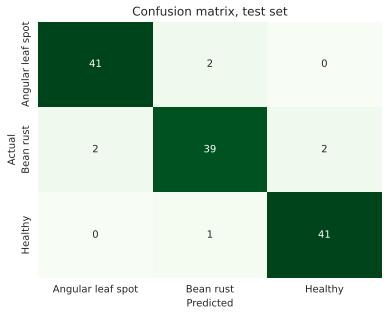

In [16]:
cm = np.array(final_metrics['confusion_matrix'])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax,
            xticklabels=[PRETTY[c] for c in CLASS_NAMES], yticklabels=[PRETTY[c] for c in CLASS_NAMES])
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Confusion matrix, test set')
plt.tight_layout(); plt.savefig('../ui/img/confusion_matrix.png', dpi=110); plt.show()

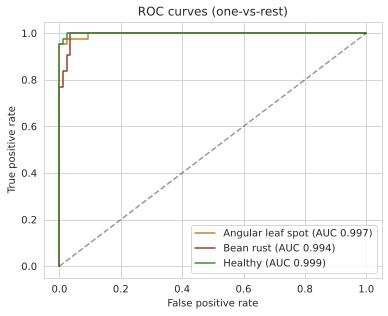

In [17]:
y_bin = label_binarize(y_true, classes=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
roc_auc = {}
for i, c in enumerate(CLASS_NAMES):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
    roc_auc[c] = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=PALETTE[c], label=f'{PRETTY[c]} (AUC {roc_auc[c]:.3f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.4)
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.set_title('ROC curves (one-vs-rest)'); ax.legend()
plt.tight_layout(); plt.show()

In [18]:
# Save the metrics so the README and the API's dashboard can show them
metrics_out = {'test': {k: final_metrics[k] for k in ['accuracy', 'loss', 'precision', 'recall', 'f1']},
               'stage1_test': {k: stage1_metrics[k] for k in ['accuracy', 'loss', 'precision', 'recall', 'f1']},
               'roc_auc': {c: float(v) for c, v in roc_auc.items()},
               'confusion_matrix': final_metrics['confusion_matrix']}
json.dump(metrics_out, open('../models/metrics.json', 'w'), indent=2)
json.dumps(metrics_out['test'], indent=1)

'{\n "accuracy": 0.9453125,\n "loss": 0.09932433068752289,\n "precision": 0.9451827242524917,\n "recall": 0.9455518641565153,\n "f1": 0.945280437756498\n}'

**Interpretation.**
- Fine-tuning helped: test accuracy went from **91.4% to 94.5%** and the loss more than halved (0.234 to 0.099). Macro precision, recall and F1 are all about 0.945, so no class is sacrificed for the average. ROC-AUC is above 0.99 for every class.
- The confusion matrix matches the data exploration: healthy leaves are right 41 times out of 42 and angular leaf spot 41 out of 43. Most errors involve bean rust: 2 rust leaves were called angular leaf spot and 2 were called healthy.
- The costly error for a farmer is a diseased leaf called healthy. That happened for 2 of the 86 diseased test leaves (2.3%). Mixing up the two diseases still raises an alert.

## Save the model

In [19]:
latest_path, version_path = save_model(model, '../models')
print('Serving model:', latest_path, f'({os.path.getsize(latest_path) / 1e6:.1f} MB)')
print('Versioned copy:', version_path)

Serving model: ../models/bean_model.h5 (10.1 MB)
Versioned copy: ../models/versions/bean_model_20261125_160623.h5


## 7. Prediction functions

`predict_image()` in `src/prediction.py` is the function behind the API's `/predict` endpoint: one image in, class and confidence out. Below it runs on one test image of each class, loading the model from the saved `.h5` file just like the API does.

angular_leaf_spot_0020.jpg {'predicted_class': 'angular_leaf_spot', 'confidence': 0.9975, 'class_probabilities': {'angular_leaf_spot': 0.9975, 'bean_rust': 0.0022, 'healthy': 0.0003}}
bean_rust_0009.jpg {'predicted_class': 'bean_rust', 'confidence': 0.6197, 'class_probabilities': {'angular_leaf_spot': 0.3803, 'bean_rust': 0.6197, 'healthy': 0.0}}


healthy_0025.jpg {'predicted_class': 'healthy', 'confidence': 1.0, 'class_probabilities': {'angular_leaf_spot': 0.0, 'bean_rust': 0.0, 'healthy': 1.0}}


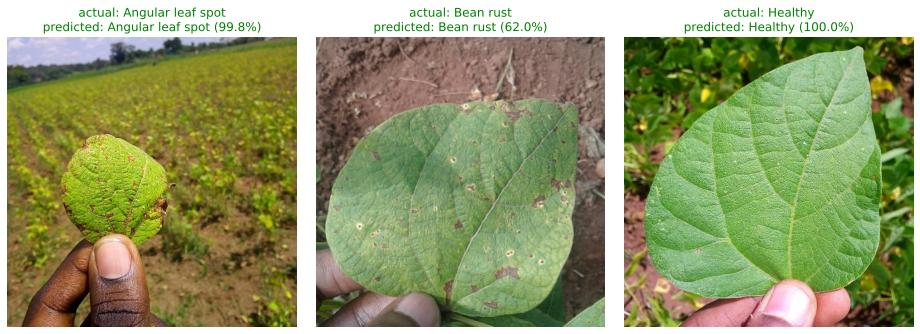

In [20]:
rng = random.Random(7)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, (i, c) in zip(axes, enumerate(CLASS_NAMES)):
    path = rng.choice([p for p, l in zip(test_paths, test_labels) if l == i])
    result = predict_image(image_path=path, model_path=latest_path)
    ok = result['predicted_class'] == c
    ax.imshow(plt.imread(path)); ax.axis('off')
    ax.set_title(f"actual: {PRETTY[c]}\npredicted: {PRETTY[result['predicted_class']]} ({result['confidence']:.1%})",
                 color='green' if ok else 'red')
    print(os.path.basename(path), result)
plt.tight_layout(); plt.show()

All three predictions are correct. The bean rust example is the hardest: the model gives 62% to bean rust and 38% to angular leaf spot, the same confusion seen in the confusion matrix. That is why the UI shows every class probability, not only the top class.

## 8. Retraining

In production, users upload new labelled images through the UI. The API stores them in the database and, when the button is pressed (or when enough new images have arrived), runs a retraining job:

1. Load the new images from the database and **preprocess** them with the same pipeline as above (+ augmentation).
2. Mix in a replay sample of the original training images so the model does not forget what it already knows.
3. **Load the current custom model as the pre-trained starting point** and continue training at a low learning rate (`retrain_model()` in `src/model.py`).
4. Evaluate the old and the new model on the same held-out test set and **promote the new one only if its macro F1 is at least as good**.

The cell below runs the same steps, using the images in `sample_images/retrain/` as the "new uploads". It writes to `models/retrain_demo/` so the serving model is untouched.

In [21]:
from preprocessing import make_dataset_from_bytes

# 1. "New uploads" (in the API these come from the SQLite database as bytes)
new_bytes, new_labels = [], []
for i, c in enumerate(CLASS_NAMES):
    folder = os.path.join('../sample_images/retrain', c)
    for name in sorted(os.listdir(folder)) if os.path.isdir(folder) else []:
        new_bytes.append(open(os.path.join(folder, name), 'rb').read()); new_labels.append(i)
print('New images:', pd.Series(new_labels).map(dict(enumerate(CLASS_NAMES))).value_counts().to_dict())

# 2. Replay sample of original training data (30 per class)
replay_p, replay_l = [], []
for i in range(NUM_CLASSES):
    replay_p += random.Random(SEED).sample([p for p, l in zip(train_paths, train_labels) if l == i], 30)
    replay_l += [i] * 30
replay_bytes = [open(p, 'rb').read() for p in replay_p]

imgs, lbls = new_bytes + replay_bytes, new_labels + replay_l
tr_i, _, va_i, _ = stratified_split(list(range(len(imgs))), lbls, val_fraction=0.2, seed=SEED)
rt_train = make_dataset_from_bytes([imgs[k] for k in tr_i], [lbls[k] for k in tr_i], 16, augment=True, shuffle=True)
rt_val = make_dataset_from_bytes([imgs[k] for k in va_i], [lbls[k] for k in va_i], 16)

# 3. Continue training from the saved custom model
old_metrics = evaluate_model(tf.keras.models.load_model(latest_path, compile=False), test_ds)
new_model, rt_hist = retrain_model(latest_path, rt_train, rt_val, epochs=3, learning_rate=1e-4, n_trainable=0, verbose=2)
new_metrics = evaluate_model(new_model, test_ds)

# 4. Compare and decide
promote = new_metrics['f1'] >= old_metrics['f1']
if promote:
    save_model(new_model, '../models/retrain_demo')
pd.DataFrame({'current model': old_metrics, 'retrained model': new_metrics}).loc[['accuracy', 'loss', 'precision', 'recall', 'f1']].round(4)

New images: {'angular_leaf_spot': 15, 'bean_rust': 15, 'healthy': 15}


Epoch 1/3


7/7 - 1s - 128ms/step - accuracy: 0.9815 - loss: 0.1264 - val_accuracy: 0.9630 - val_loss: 0.1907 - learning_rate: 1.0000e-04


Epoch 2/3


7/7 - 0s - 16ms/step - accuracy: 0.9630 - loss: 0.1152 - val_accuracy: 0.9630 - val_loss: 0.2080 - learning_rate: 1.0000e-04


Epoch 3/3


7/7 - 0s - 16ms/step - accuracy: 0.9630 - loss: 0.0907 - val_accuracy: 0.9630 - val_loss: 0.2097 - learning_rate: 3.0000e-05


,current model,retrained model
accuracy,0.945312,0.945312
loss,0.099324,0.097554
precision,0.945183,0.945183
recall,0.945552,0.945552
f1,0.94528,0.94528


In [22]:
print('Promote retrained model:', promote)

Promote retrained model: True


The retrained model is compared with the current one on the same 128 test images before anything is replaced. Here the 45 new images kept accuracy and F1 the same (94.5%) and lowered the loss slightly (0.099 to 0.098), so the new model was promoted (ties are promoted). The rule matters most when a batch of uploads is mislabelled or poor: then the retrained model scores lower and the served model is kept.

## Summary
- Fine-tuned MobileNetV2 reaches **94.5% accuracy, macro F1 0.945 and ROC-AUC above 0.99** on the 128 held-out test images, up from 91.4% with the frozen base.
- Colour separates healthy from diseased leaves but not the two diseases, and the remaining errors are exactly there.
- Retraining continues from the saved model, is checked on the test set, and is only promoted when it is at least as good.
- The model is saved as `models/bean_model.h5` and served by the FastAPI app, which reuses `src/`.